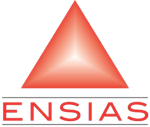

# TP 5 — Support Vector Machine (SVM)

**Module :** Introduction au Machine Learning
**Enseignant :** Prof. Aissam BERRAHOU — ENSIAS, Université Mohammed V de Rabat
**Niveau :** 2e année cycle ingénieur
**Durée estimée :** 2 heures
**Support associé :** Lecture 5 — SVM

## 1. Objectifs pédagogiques

*Ce TP prolonge le cours : vous allez refaire sur machine les calculs vus en séance, puis passer à un vrai jeu de données.*

1. Retrouver **w, b, la marge et les vecteurs de support** de l'exemple des slides.
2. Vérifier les contraintes $y_i(w \cdot x_i + b) \geq 1$ avec NumPy.
3. Observer l'effet du paramètre **C** (marge souple).
4. Comprendre le **kernel trick** et le noyau **RBF** (paramètre $\gamma$).
5. Régler C et $\gamma$ par **GridSearchCV** sur la base Breast Cancer.

## 2. Rappel théorique

*Avant de coder, un rapide rappel des formules dont nous aurons besoin.*

Règle de décision : $f(x) = w \cdot x + b$, classe $= \text{signe}(f(x))$.

**Marge dure :** $\min_{w,b} \tfrac{1}{2}\lVert w\rVert^2$ sous $y_i(w\cdot x_i + b) \ge 1$ ; marge $= 2/\lVert w\rVert$.

**Marge souple :** $\min \tfrac{1}{2}\lVert w\rVert^2 + C\sum_i \xi_i$ sous $y_i(w\cdot x_i+b) \ge 1-\xi_i$, $\xi_i \ge 0$.

**Noyau RBF :** $K(x, x') = \exp(-\gamma \lVert x - x'\rVert^2)$.

## 3. Import des bibliothèques

*On charge d'abord les outils. Tout le TP n'utilise que NumPy, pandas, Matplotlib et scikit-learn.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.datasets import make_moons, load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

## 4. Exemple jouet : 6 points séparables

*Retrouvons, sur machine, l'hyperplan calculé à la main dans le cours.*

In [2]:
X = np.array([[1, 1], [2, 1], [1, 2], [3, 3], [4, 3], [3, 4]], dtype=float)
y = np.array([-1, -1, -1, 1, 1, 1])
pd.DataFrame(X, columns=["x1", "x2"], index=[f"P{i}" for i in range(1, 7)]).assign(classe=y)

,x1,x2,classe
P1,1.0,1.0,-1
P2,2.0,1.0,-1
P3,1.0,2.0,-1
P4,3.0,3.0,1
P5,4.0,3.0,1
P6,3.0,4.0,1


### 4.1 La solution calculée à la main dans les slides

*Notre solution respecte-t-elle bien toutes les contraintes ?*

$w = (2/3, 2/3)$, $b = -3$. Vérifions les contraintes :

In [3]:
w = np.array([2 / 3, 2 / 3])
b = -3
f = X @ w + b                          # f(x_i) = w · x_i + b
tableau = pd.DataFrame({"f(x)": f.round(3), "y·f(x)": (y * f).round(3),
                        "contrainte ≥ 1": y * f >= 1 - 1e-9,
                        "vecteur de support": np.isclose(np.abs(f), 1)})
print("marge = 2/‖w‖ =", round(2 / np.linalg.norm(w), 3))
tableau

marge = 2/‖w‖ = 2.121


,f(x),y·f(x),contrainte ≥ 1,vecteur de support
0,-1.667,1.667,True,False
1,-1.000,1.000,True,True
2,-1.000,1.000,True,True
3,1.000,1.000,True,True
4,1.667,1.667,True,False
5,1.667,1.667,True,False


### 4.2 Vérification avec scikit-learn

*scikit-learn trouve-t-il le même hyperplan ?*

Un C très grand reproduit la **marge dure**.

In [4]:
svm = SVC(kernel="linear", C=1e6).fit(X, y)
print("w =", svm.coef_.round(3), "  b =", svm.intercept_.round(3))
print("vecteurs de support :\n", svm.support_vectors_)
print("prédiction pour (2, 3) :", svm.predict([[2, 3]]), "  f =", svm.decision_function([[2, 3]]).round(3))

w = [[0.667 0.666]]   b = [-3.]
vecteurs de support :
 [[2. 1.]
 [1. 2.]
 [3. 3.]]
prédiction pour (2, 3) : [1]   f = [0.333]


### 4.3 Visualisation de l'hyperplan et de la marge

*Une image pour voir la marge et ses vecteurs de support.*

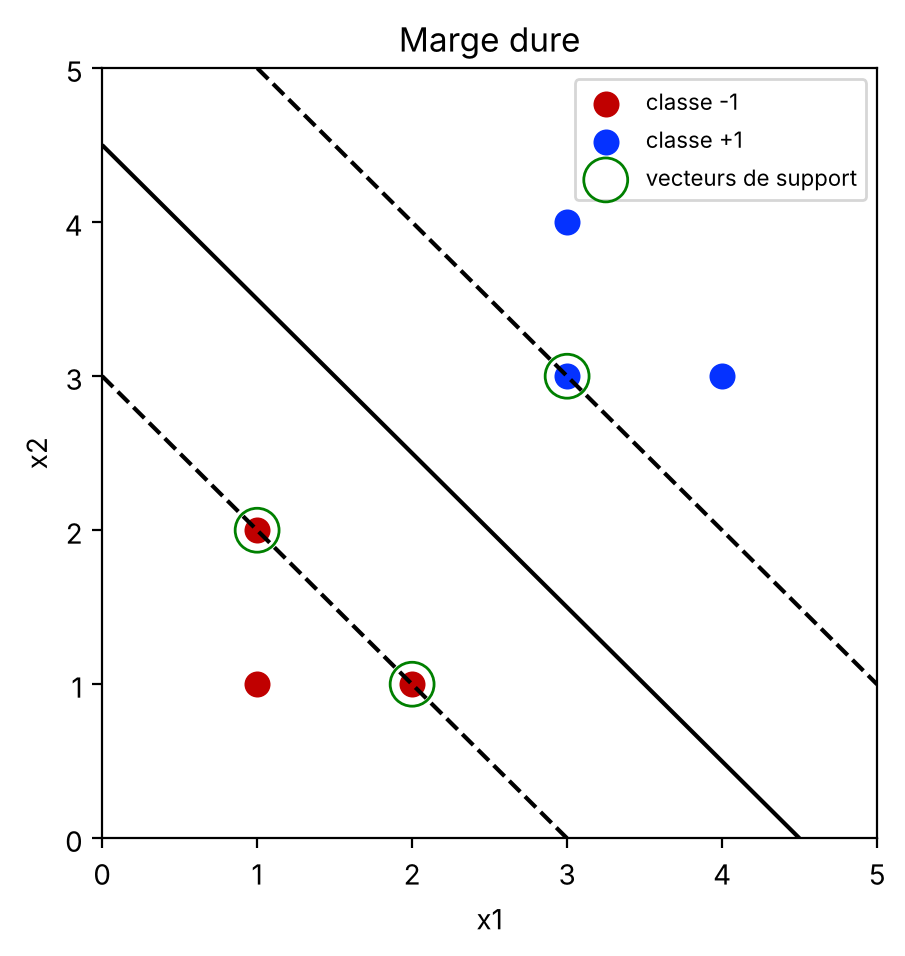

In [5]:
def tracer_svm(modele, X, y, ax, titre):
    xx, yy = np.meshgrid(np.linspace(0, 5, 200), np.linspace(0, 5, 200))
    Z = modele.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
    ax.scatter(*X[y == -1].T, c="#C00000", s=70, label="classe -1")
    ax.scatter(*X[y == 1].T, c="#0532FF", s=70, label="classe +1")
    sv = modele.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=250, facecolors="none", edgecolors="green", label="vecteurs de support")
    ax.set_title(titre); ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(fontsize=8)

fig, ax = plt.subplots(figsize=(5, 5)); tracer_svm(svm, X, y, ax, "Marge dure"); plt.show()

## 5. Marge souple : influence de C

*Que fait le SVM face à un point mal placé ?*

On ajoute le point gênant $P_7(2.5, 2.5)$ de classe $-1$.

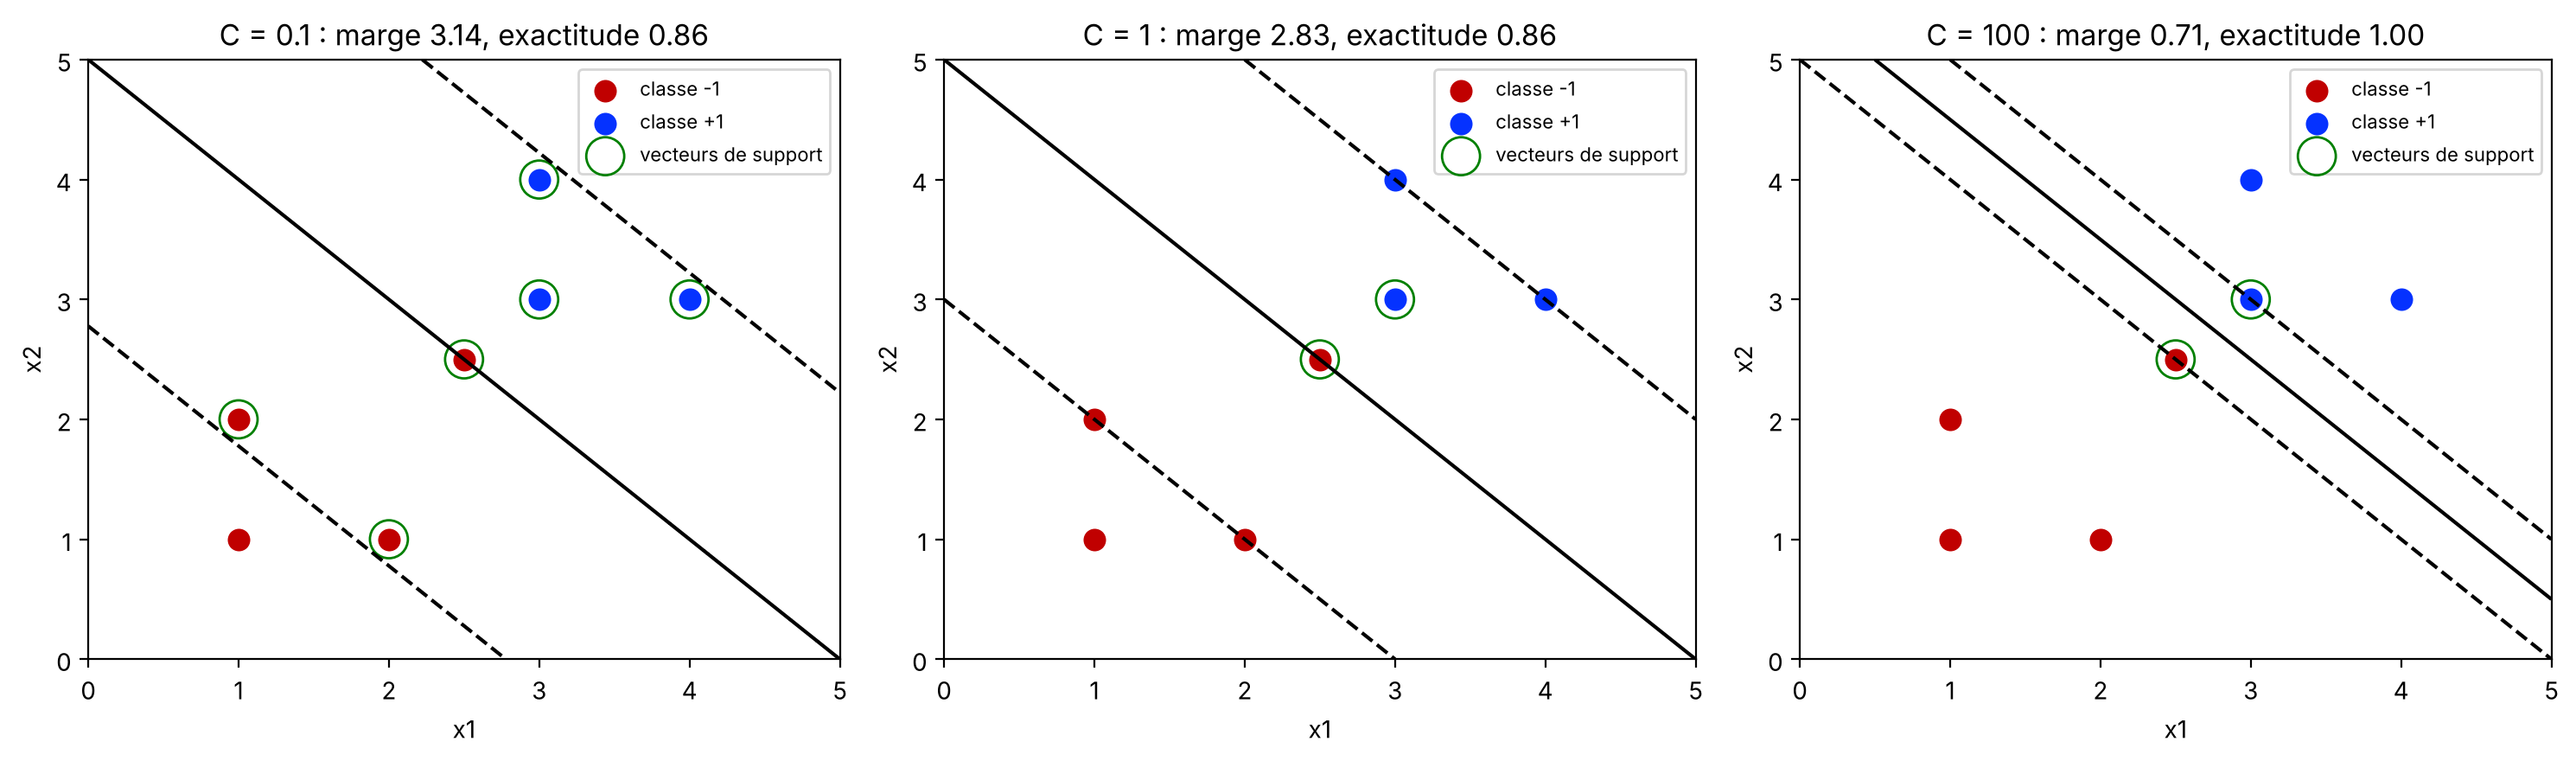

In [6]:
X7 = np.vstack([X, [2.5, 2.5]])
y7 = np.append(y, -1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for C, ax in zip([0.1, 1, 100], axes):
    m = SVC(kernel="linear", C=C).fit(X7, y7)
    marge = 2 / np.linalg.norm(m.coef_)
    tracer_svm(m, X7, y7, ax, f"C = {C} : marge {marge:.2f}, exactitude {m.score(X7, y7):.2f}")
plt.tight_layout(); plt.show()

C petit → marge large, P7 est mal classé ; C grand → P7 bien classé, mais marge très étroite.

## 6. Kernel trick

*Comment séparer des données qu'aucune droite ne sépare ?*

### 6.1 En dimension 1 : la transformation $\varphi(x) = (x, x^2)$

*Une dimension de plus, et tout devient séparable.*

In [7]:
x1d = np.array([-3, -2, -1, 0, 1, 2, 3], dtype=float)
y1d = np.array([1, 1, -1, -1, -1, 1, 1])
phi = np.column_stack([x1d, x1d ** 2])           # passage en dimension 2
m = SVC(kernel="linear", C=1e6).fit(phi, y1d)
print("Exactitude dans l'espace (x, x²) :", m.score(phi, y1d))
print("Hyperplan : w =", m.coef_.round(3), " b =", m.intercept_.round(3))

Exactitude dans l'espace (x, x²) : 1.0
Hyperplan : w = [[0.    0.667]]  b = [-1.667]


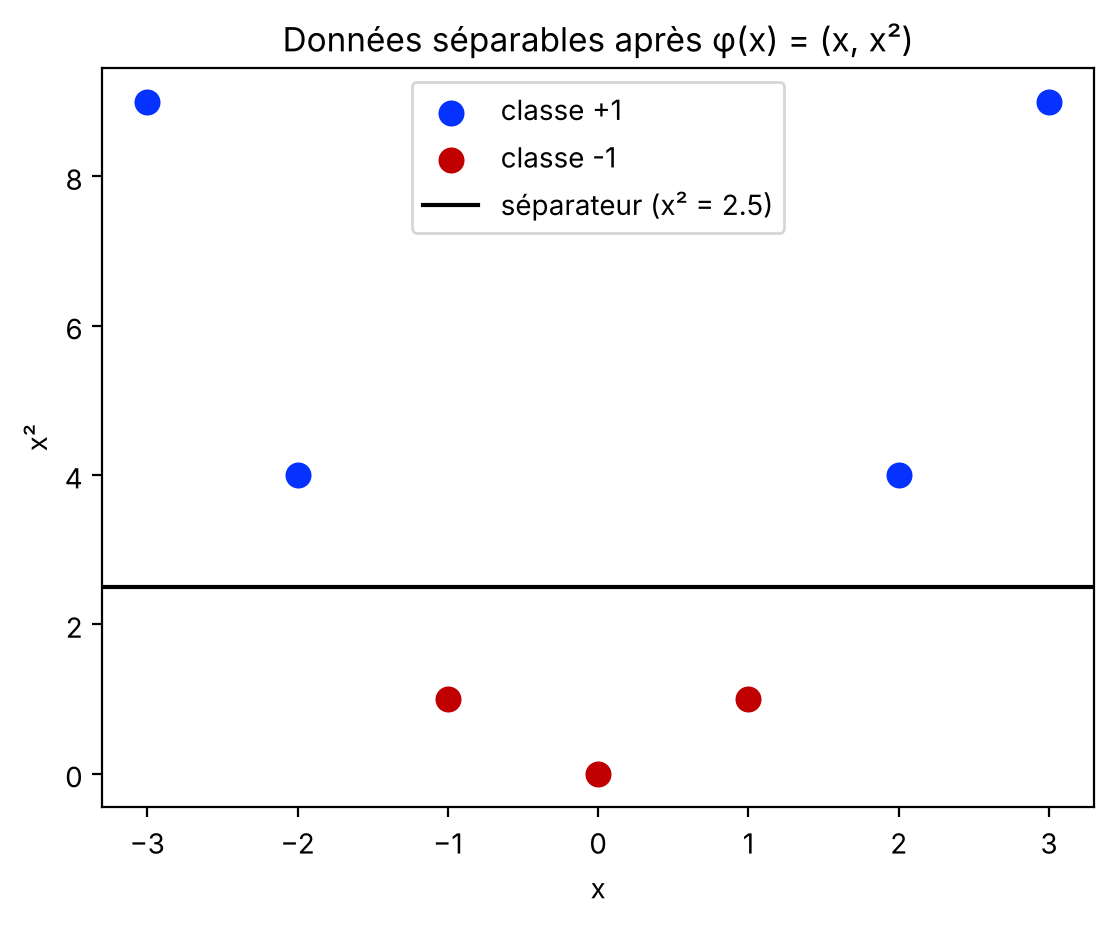

In [8]:
plt.scatter(x1d[y1d == 1], x1d[y1d == 1] ** 2, c="#0532FF", s=70, label="classe +1")
plt.scatter(x1d[y1d == -1], x1d[y1d == -1] ** 2, c="#C00000", s=70, label="classe -1")
plt.axhline(-m.intercept_[0] / m.coef_[0, 1], color="k", label="séparateur (x² = 2.5)")
plt.xlabel("x"); plt.ylabel("x²"); plt.legend(); plt.title("Données séparables après φ(x) = (x, x²)"); plt.show()

### 6.2 Noyau RBF sur `make_moons`

*Linéaire, polynomial ou RBF : quel noyau pour des lunes ?*

In [9]:
X_m, y_m = make_moons(300, noise=0.2, random_state=42)
Xm_train, Xm_test, ym_train, ym_test = train_test_split(X_m, y_m, test_size=0.3, random_state=42)
for noyau in ["linear", "poly", "rbf"]:
    m = SVC(kernel=noyau, C=1, degree=3).fit(Xm_train, ym_train)
    print(f"{noyau:6s} : exactitude test = {m.score(Xm_test, ym_test):.3f}")

linear : exactitude test = 0.900
poly   : exactitude test = 0.911
rbf    : exactitude test = 0.967


## 7. Influence des hyperparamètres C et $\gamma$ (noyau RBF)

*Jusqu'où peut-on assouplir la frontière avant de surapprendre ?*

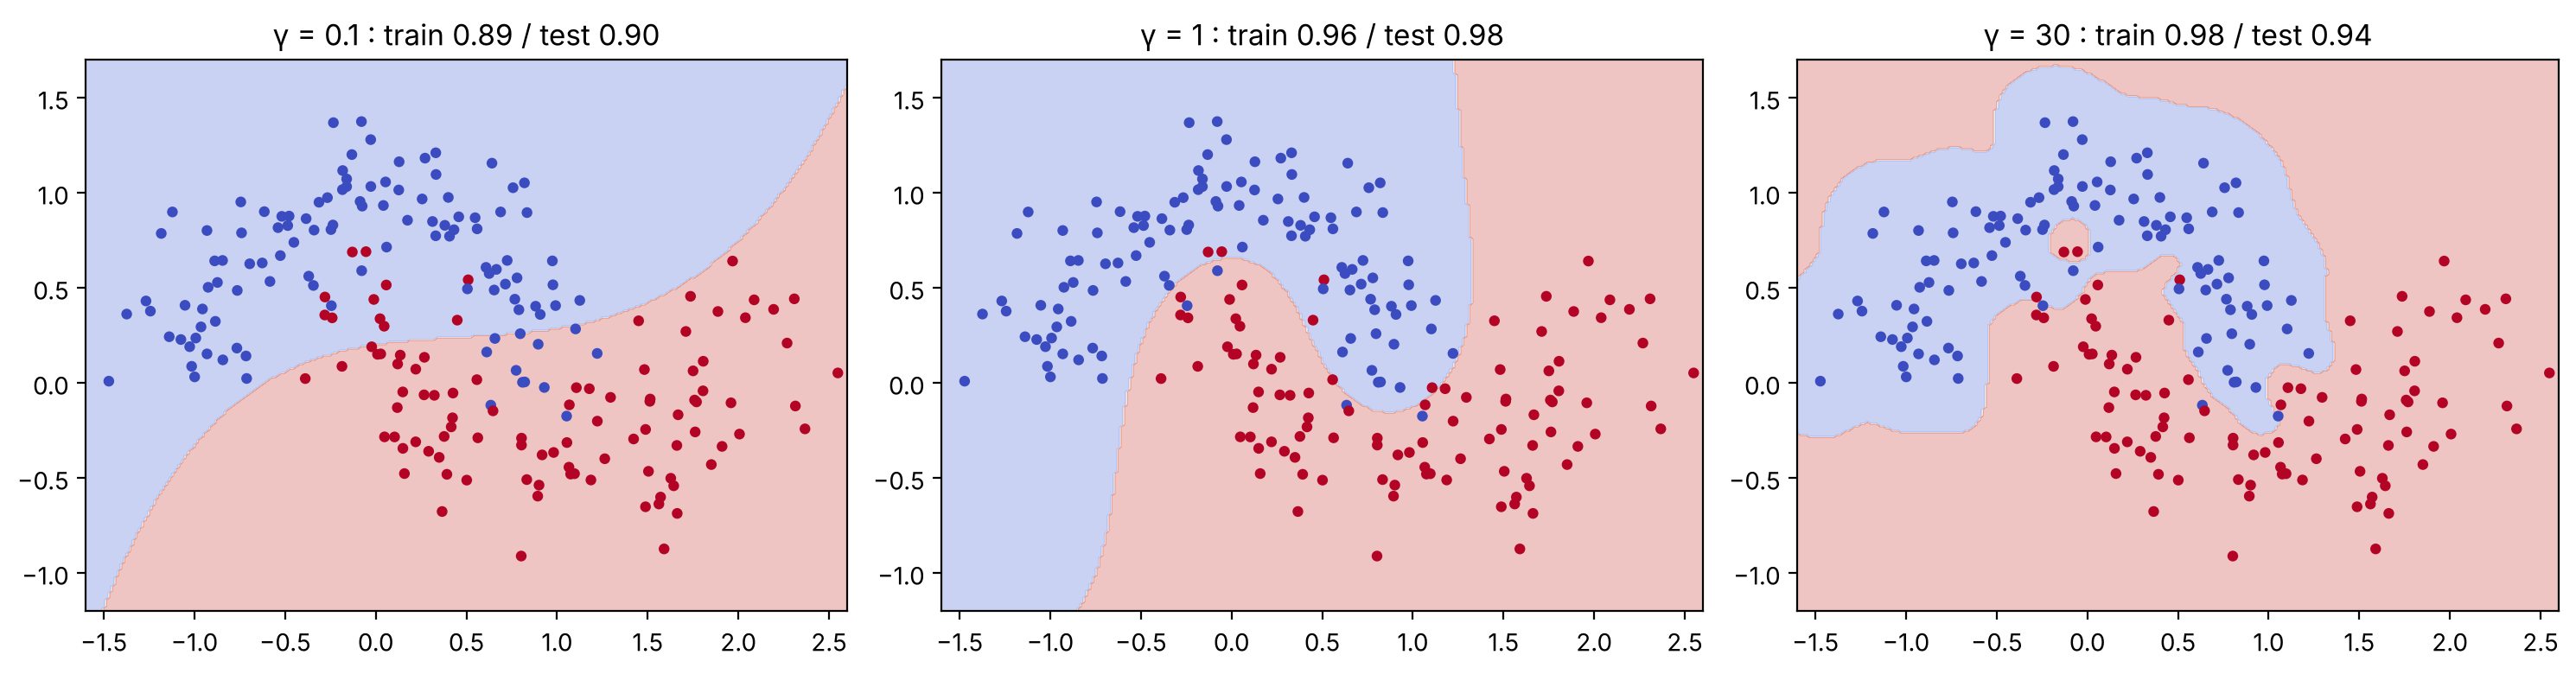

In [10]:
xx, yy = np.meshgrid(np.linspace(-1.6, 2.6, 250), np.linspace(-1.2, 1.7, 250))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for gamma, ax in zip([0.1, 1, 30], axes):
    m = SVC(kernel="rbf", C=10, gamma=gamma).fit(Xm_train, ym_train)
    Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm"); ax.scatter(*Xm_train.T, c=ym_train, cmap="coolwarm", s=12)
    ax.set_title(f"γ = {gamma} : train {m.score(Xm_train, ym_train):.2f} / test {m.score(Xm_test, ym_test):.2f}")
plt.tight_layout(); plt.show()

γ trop grand : la frontière épouse chaque point (excellente sur l'apprentissage, moins bonne en test) : **surapprentissage**.

## 8. Cas pratique : la base Breast Cancer

*569 tumeurs, 30 mesures : le SVM saura-t-il les classer ?*

569 tumeurs, 30 variables, 2 classes (maligne / bénigne). On **standardise** puis on règle C et γ par validation croisée.

In [11]:
cancer = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, test_size=0.25, random_state=42, stratify=cancer.target)

pipeline = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
grille = {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.001, 0.01, 0.1, 1]}
recherche = GridSearchCV(pipeline, grille, cv=5).fit(X_train, y_train)
print("Meilleurs paramètres :", recherche.best_params_)
print("Exactitude CV :", round(recherche.best_score_, 3))

Meilleurs paramètres : {'svc__C': 10, 'svc__gamma': 0.001}
Exactitude CV : 0.977


### 8.1 Évaluation finale sur le test

*Le moment de vérité : la performance sur des données jamais vues.*

In [12]:
y_pred = recherche.predict(X_test)
print("Exactitude test :", round(accuracy_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred, target_names=cancer.target_names))

Exactitude test : 0.979
              precision    recall  f1-score   support

   malignant       0.98      0.96      0.97        53
      benign       0.98      0.99      0.98        90

    accuracy                           0.98       143
   macro avg       0.98      0.98      0.98       143
weighted avg       0.98      0.98      0.98       143



## 9. Exercices

*À vous de jouer ! Les exercices sont classés du plus simple au plus exigeant. Essayez de les faire sans regarder les solutions.*

### Exercice 1 (facile) — Retirer un point
Retirez $P_5(4, 3)$ (qui n'est pas un vecteur de support) et réentraînez le SVM linéaire à marge dure. L'hyperplan change-t-il ? Et si vous retirez $P_4(3, 3)$ ?

In [13]:
# À compléter

### Exercice 2 (moyen) — Sans standardisation
Refaites la recherche de la section 8 **sans** `StandardScaler`. Comparez l'exactitude de test et expliquez.

In [14]:
# À compléter

### Exercice 3 (défi) — Noyau calculé à la main
Calculez la matrice de Gram $K_{ij} = \exp(-\gamma \lVert x_i - x_j\rVert^2)$ pour `Xm_train` avec $\gamma = 1$, puis entraînez `SVC(kernel="precomputed")`. Vérifiez que vous obtenez la même exactitude qu'avec `kernel="rbf", gamma=1`.

In [15]:
# À compléter

## 10. Solutions

*Comparez vos réponses avec les propositions ci-dessous ; il existe souvent plusieurs façons correctes de faire.*

<details>
<summary><b>Solution de l'exercice 1</b> (cliquer pour afficher)</summary>

```python
for retire in [4, 3]:                      # indice de P5 puis de P4
    garde = np.arange(6) != retire
    m = SVC(kernel="linear", C=1e6).fit(X[garde], y[garde])
    print(f"sans P{retire + 1} : w = {m.coef_.round(3)}, b = {m.intercept_.round(3)}")
```
Retirer P5 ne change rien (ce n'est pas un vecteur de support). Retirer P4 change l'hyperplan : la marge s'élargit.
</details>

<details>
<summary><b>Solution de l'exercice 2</b> (cliquer pour afficher)</summary>

```python
brut = GridSearchCV(SVC(kernel="rbf"), {"C": [0.1, 1, 10, 100], "gamma": [0.001, 0.01, 0.1, 1]}, cv=5)
brut.fit(X_train, y_train)
print(brut.best_params_, round(brut.score(X_test, y_test), 3))
```
Sans standardisation, les variables de grande échelle (aires en mm²) dominent les distances du noyau RBF : l'exactitude baisse.
</details>

<details>
<summary><b>Solution de l'exercice 3</b> (cliquer pour afficher)</summary>

```python
def gram(A, B, gamma=1.0):
    d2 = ((A[:, None, :] - B[None, :, :]) ** 2).sum(axis=2)
    return np.exp(-gamma * d2)

m = SVC(kernel="precomputed").fit(gram(Xm_train, Xm_train), ym_train)
print(m.score(gram(Xm_test, Xm_train), ym_test),
      SVC(kernel="rbf", gamma=1).fit(Xm_train, ym_train).score(Xm_test, ym_test))
```
</details>

## 11. Conclusion — ce qu'il faut retenir

*Avant de passer à la suite, prenons une minute pour résumer l'essentiel.*

- Le SVM cherche l'hyperplan de **marge maximale** ; seuls les **vecteurs de support** comptent.
- **C** règle le compromis marge large / erreurs d'apprentissage.
- Les **noyaux** (polynomial, RBF) donnent des frontières non linéaires ; **γ** règle leur souplesse.
- Toujours **standardiser** et régler C, γ par **validation croisée**.

➡️ Prochain cours : K-means.